# IA Hybride et Apprentissage Automatique (L6SOIAAU)<br>
## TD 9 : Implémentation des CNN et des RNN
### Exercices avec `keras` et `pytorch`

Ljudmila PETKOVIC<br>
Licence « Sciences du langage » (L3)<br>
Sorbonne Université, UFR Sociologie et Informatique pour les Sciences Humaines<br>
03/04/2026

Ce cahier regroupe 22 exercices.



# CNN

## Classification des images d'animaux

Basé sur le code `Reuse_vgg16.ipynb` de [Khichane (2025)](https://www.editions-eni.fr/livre/le-machine-learning-et-l-ia-generative-avec-python-de-la-theorie-a-la-pratique-2e-edition-9782409050015).

In [ ]:
import tensorflow as tf
from tensorflow import keras
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications import vgg16

os.environ['TF_CPP_MIN_LOG_LEVEL']='2'

model = vgg16.VGG16()

img_src = image.load_img("border-collie-2648945_1920.jpg", target_size=(224,224))
img_test = image.img_to_array(img_src)

img_test_lst = np.expand_dims(img_test, axis=0)

img_test_lst = vgg16.preprocess_input(img_test_lst)

predictions = model.predict(img_test_lst)


predected_classes = vgg16.decode_predictions(predictions, top=5)

print(predected_classes)

## Classification des articles BBC

Basé sur le code de [Raza (2024)](https://medium.com/@aliraza.abro.prog/convolutional-neural-networks-cnns-for-text-classification-bd473c7285a4).

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Dense, Input, Embedding, Conv1D, MaxPooling1D, GlobalMaxPooling1D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.losses import SparseCategoricalCrossentropy

# Load the dataset
df = pd.read_csv("./BBC_Text_CLS.csv")

# Display the first few rows of the dataset
print(df.head(5))

# Convert labels to numerical targets
df["targets"] = df["labels"].astype("category").cat.codes

# Determine the number of classes
K = df["targets"].nunique()

# Split the dataset into training and test sets
train, test = train_test_split(df, test_size=0.3, random_state=42)

# Define maximum vocabulary size
MAX_VOCAB_SIZE = 2000

# Initialize the tokenizer
tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)

# Fit the tokenizer on the training texts
tokenizer.fit_on_texts(train["text"])

# Convert texts to sequences
seq_train = tokenizer.texts_to_sequences(train["text"])
seq_test = tokenizer.texts_to_sequences(test["text"])

# Get the word index mapping
word2idx = tokenizer.word_index

# Vocabulary size
V = len(word2idx)  # Number of unique words in the corpus
print(f"Vocabulary size: {V}")

# Determine the maximum sequence length for padding
data_train = pad_sequences(seq_train)
data_test = pad_sequences(seq_test, maxlen=data_train.shape[1])

# Extract the sequence length
T = data_train.shape[1]
print(f"Sequence length: {T}")

                                                text    labels
0  Ad sales boost Time Warner profit\n\nQuarterly...  business
1  Dollar gains on Greenspan speech\n\nThe dollar...  business
2  Yukos unit buyer faces loan claim\n\nThe owner...  business
3  High fuel prices hit BA's profits\n\nBritish A...  business
4  Pernod takeover talk lifts Domecq\n\nShares in...  business
Vocabulary size: 27758
Sequence length: 2837


In [ ]:
classes = (
    df[['targets', 'labels']]
    .drop_duplicates()
    .sort_values('targets')
)

for _, row in classes.iterrows():
    print(f"{row['targets']} -> {row['labels']}")

0 -> business
1 -> entertainment
2 -> politics
3 -> sport
4 -> tech


In [ ]:
MAX_SEQUENCE_LENGTH = 100

# Pad sequences to ensure uniform input length
data_train = pad_sequences(seq_train, maxlen=MAX_SEQUENCE_LENGTH, padding='post')
data_test = pad_sequences(seq_test, maxlen=MAX_SEQUENCE_LENGTH, padding='post')

print(f"Shape of data_train: {data_train.shape}, Shape of data_test: {data_test.shape}")

Shape of data_train: (1557, 100), Shape of data_test: (668, 100)


In [ ]:
# Extract the sequence length for model input
T = data_train.shape[1]
print(f"Sequence length: {T}")

"""
This sets the size of the dense vectors that each word will be converted
into by the Embedding layer. In this case, each word will be represented
by a vector of 50 dimensions.
"""
EMBEDDING_DIM = 50

"""
Defines the input layer of the model. The shape of the input is (T,),
where T is the maximum sequence length after padding. Each input is a sequence
of integers (word indices) representing words in the text, padded to have
a uniform length.
"""
input_ = Input(shape=(T,))

"""
Transforms the sequence of word indices into dense vectors of fixed
size (EMBEDDING_DIM).

input_dim=V + 1 specifies the size of the vocabulary (number of unique
words plus one for zero padding).
"""
x = Embedding(input_dim=V + 1, output_dim=EMBEDDING_DIM)(input_)

"""
Applies a 1D convolution to the input sequences

filters=128 specifies the number of convolutional filters
(or kernels) used to scan through the sequence.

kernel_size=5 defines the size of the filter (5 words at a time).

activation="relu" applies the ReLU activation function to
introduce non-linearity.

MaxPooling1D(pool_size=2) performs max pooling to reduce the
dimensionality of the output from the convolutional layer. It
retains the maximum value over a window of size 2.
"""
x = Conv1D(filters=128, kernel_size=5, activation="relu")(x)
x = MaxPooling1D(pool_size=2)(x)

"""
Similar to the first convolutional layer but with different parameters.
"""
x = Conv1D(filters=64, kernel_size=5, activation="relu")(x)
x = MaxPooling1D(pool_size=2)(x)

"""
Another convolutional layer followed by global max pooling.

filters=64 uses the same number of filters as the second layer.

kernel_size=5 remains the same.

GlobalMaxPooling1D() performs global max pooling, which takes
the maximum value from each feature map across the entire
sequence. This converts the output into a fixed-size vector
regardless of the sequence length.
"""
x = Conv1D(filters=64, kernel_size=5, activation="relu")(x)
x = GlobalMaxPooling1D()(x)

"""
Applies dropout regularization to the output of the previous layer.

0.5 specifies that 50% of the neurons will be randomly dropped
during training. This helps prevent overfitting by making the
model more robust.
"""
x = Dropout(0.5)(x)

"""
Defines the output layer of the model

Dense(K) creates a fully connected layer with K units
(one for each class).

activation="softmax" applies the softmax function to produce
a probability distribution over the K classes.
"""
output = Dense(K, activation="softmax")(x)

# Define the model
model = Model(inputs=input_, outputs=output)

# Compile the model
model.compile(
    loss=SparseCategoricalCrossentropy(),
    optimizer="adam",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()

Sequence length: 100


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_4 (Embedding)         │ (None, 100, 50)        │     1,387,950 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 96, 128)        │        32,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 48, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 44, 64)         │        41,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 22, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 18, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_3          │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,481,971 (5.65 MB)

 Trainable params: 1,481,971 (5.65 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.2229 - loss: 1.6072 - val_accuracy: 0.2096 - val_loss: 1.6059
Epoch 2/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.2556 - loss: 1.5836 - val_accuracy: 0.3802 - val_loss: 1.5284
Epoch 3/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.3963 - loss: 1.3399 - val_accuracy: 0.4985 - val_loss: 1.1459
Epoch 4/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.5273 - loss: 1.0480 - val_accuracy: 0.5808 - val_loss: 0.9483
Epoch 5/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.6557 - loss: 0.7916 - val_accuracy: 0.6751 - val_loss: 0.8085
Epoch 6/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.7868 - loss: 0.5427 - val_accuracy: 0.7874 - val_loss: 0.6528
Epoch 7/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8735 - loss: 0.3393 - val_accuracy: 0.8189 - val_loss: 0.5614
Epoch 8/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.9332 - loss: 0.1990 - val_accuracy: 0.8204 - v

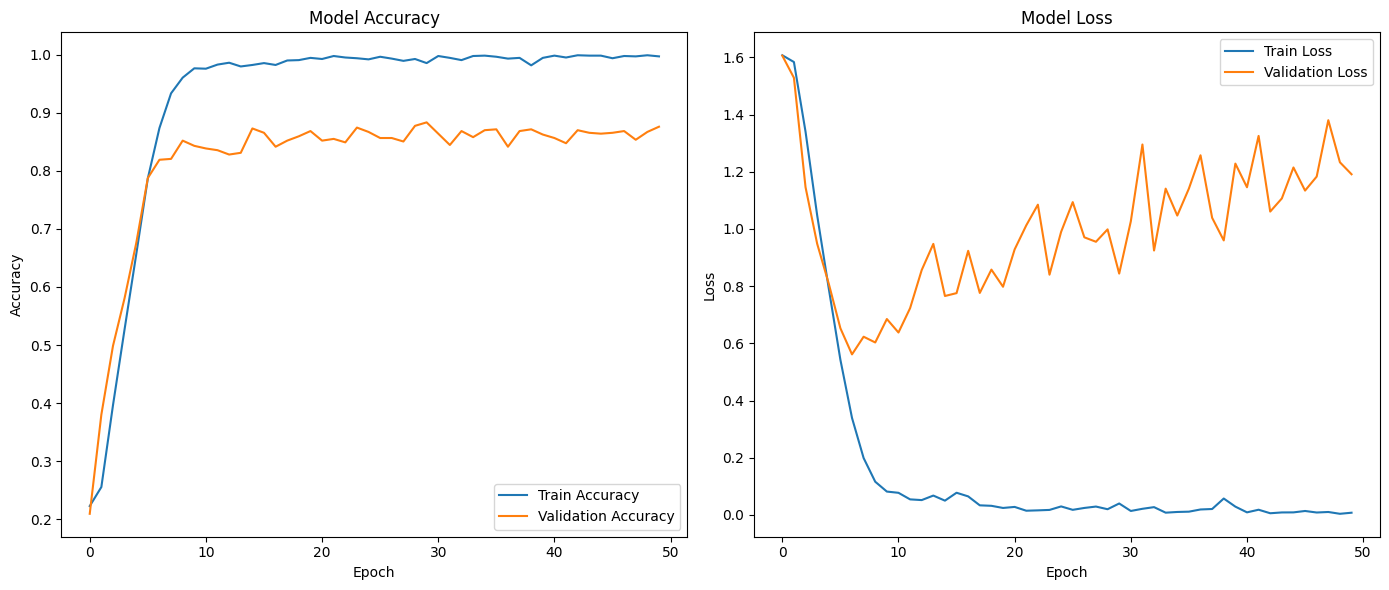

In [ ]:
# Train the model
history = model.fit(
    data_train,
    train["targets"],
    epochs=50,
    validation_data=(data_test, test["targets"])
)

# Plot training & validation accuracy values
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences



seq_new = tokenizer.texts_to_sequences(new_texts)
data_new = pad_sequences(seq_new, maxlen=100, padding='post')

predictions = model.predict(data_new)
predicted_classes = np.argmax(predictions, axis=1)
predicted_probas = np.max(predictions, axis=1)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step


In [ ]:
# Prepare new text for prediction
new_texts = ["The prime minister faced criticism over the new government policy."]
seq_new = tokenizer.texts_to_sequences(new_texts)
data_new = pad_sequences(seq_new, maxlen=MAX_SEQUENCE_LENGTH, padding='post')

# Get predictions
predictions = model.predict(data_new)

# Get the predicted class indices
predicted_classes = np.argmax(predictions, axis=1)

# Create label mapping
label_mapping = dict(zip(df['targets'].unique(), df['labels'].unique()))

# Convert class indices back to class labels
predicted_labels = get_labels_from_indices(predicted_classes, label_mapping)

print(f"Predicted class indices: {predicted_classes}")
print(f"Predicted class labels: {predicted_labels}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Predicted class indices: [2]
Predicted class labels: ['politics']


### Questions
1. Dans l'affichage suivant :
    ```
    Epoch 1/50
    49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.2229 - loss: 1.6072 - val_accuracy: 0.2096 - val_loss: 1.6059
    Epoch 2/50
    49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.2556 - loss: 1.5836 - val_accuracy: 0.3802 - val_loss: 1.5284
    ```
    expliquez ce que signifient les nombres 50 et 49.
    
    Une époque est-elle la même chose qu’une itération ?

2.   Le modèle actuel est-il entraîné avec combien d'époques ?

3. Expliquez la différence entre la `train accuracy` (précision sur l’entraînement) et la `validation accuracy` (précision sur la validation). À quoi servent-elles, et que montrent-elles sur ces graphiques ?

4. Expliquez la différence entre la `train loss` (perte sur l'entraînement) et la `validation loss` (perte sur la validation). À quoi servent-elles, et que montrent-elles sur ces graphiques ?

5.   À partir de quelle époque observe-t-on un surapprentissage, et quels indices sur les deux graphiques permettent de le voir ?

6. Modifier le code pour entraîner le modèle pendant seulement 5 époques, puis affiche les courbes d’`accuracy` et de `loss`.

7. Comparer brièvement avec l’entraînement plus long : que remarquez-vous ?

8. Remplacer `new_texts` par 3 phrases de votre choix, puis afficher pour chacune :

    * la phrase,
    * la classe prédite,
    * la probabilité maximale prédite par le modèle.

9. Dans le code, les textes sont convertis en séquences d’indices avec `Tokenizer`, puis complétés avec `pad_sequences(..., maxlen=100, padding='post')`. Expliquer :

    * à quoi sert la tokenisation ;
    * pourquoi il faut que toutes les séquences aient la même longueur ;
    * ce que signifie `padding='post'`.

10. Expliquer ce qu’est un _tenseur_ en deep learning.

    En quoi un tenseur se distingue-t-il d’un scalaire, d’un vecteur et d’une matrice ?

    Donner aussi un exemple de tenseur utilisé dans un réseau de neurones.

11. Le modèle commence par une couche `Embedding(input_dim=V+1, output_dim=50)`, puis applique des couches `Conv1D`. Expliquer :

    * ce que représente la sortie de la couche d’embedding ;
    * ce que fait une convolution 1D sur du texte ;
    * pourquoi un noyau de taille 5 peut être utile en classification de texte.

12. Le code utilise `MaxPooling1D`, puis `GlobalMaxPooling1D`, puis `Dropout(0.5)`.

    Donner le rôle de chacune de ces trois opérations dans le modèle.



### Réponses

 1. Une **époque** est un passage complet sur toutes les données d’entraînement.

    Une **itération** est une seule mise à jour du modèle sur un *batch* (nombre d’exemples que le modèle traite en une seule fois avant de faire une mise à jour de ses poids).
    
    Dans Epoch 1/50, le 1 indique l’**époque en cours** et le 50 le **nombre total d’époques prévues**.
    
    Dans 49/49, le 49 désigne le **49<sup>e</sup> batch** traité sur 49 batches au total pendant cette époque.
 2.   Le modèle actuel est entraîné avec **50 époques**.

  3. La `train accuracy` est la proportion de bonnes prédictions sur les données d’entraînement. Elle mesure **à quel point le modèle réussit sur les exemples qu’il a vus pendant l’apprentissage**.

      La `validation accuracy` est la proportion de bonnes prédictions sur les données de validation, c’est-à-dire sur des données non utilisées pour ajuster les poids du modèle. Elle permet d’**évaluer la capacité du modèle à généraliser**.

      Sur ces graphiques :

      la `train accuracy` augmente continuellement et atteint presque 1, ce qui montre que le modèle apprend très bien les données d’entraînement ;
      la `validation accuracy` augmente au début, puis se stabilise autour de 0,85–0,87, sans suivre la même progression que la `train accuracy`.

      Cela montre que **le modèle devient de plus en plus performant sur les données d’entraînement**, mais que **ses performances sur des données nouvelles n’augmentent plus vraiment**. L’écart croissant entre les deux accuracies indique donc un **surapprentissage**.

  4. La `train loss` est la valeur de la fonction de perte calculée sur les données d’entraînement. Elle mesure **à quel point le modèle s’ajuste aux exemples qu’il voit pendant l’apprentissage**.

      La `validation loss` est la valeur de la fonction de perte calculée sur les données de validation, c’est-à-dire sur des données que le modèle n’utilise pas pour mettre à jour ses poids pendant l’entraînement. Elle sert à **évaluer la capacité de généralisation du modèle**.

      La fonction de perte **mesure l’erreur du modèle**, c’est-à-dire **la quantité qu’il cherche à minimiser pendant l’entraînement.**

      Sur ces graphiques :

      * la `train loss` diminue continuellement, ce qui montre que **le modèle apprend de mieux en mieux les données d’entraînement** ;
      * la `validation loss` diminue au début, puis remonte, ce qui montre qu’**après quelques époques le modèle commence à moins bien généraliser**.

      Autrement dit, la `train loss` indique la qualité d’apprentissage sur les données vues, tandis que la `validation loss` indique la qualité du modèle sur des données non vues. Ici, l’écart croissant entre les deux suggère un **surapprentissage**.
  5.   On commence à observer un surapprentissage **à partir d’environ l’époque 4 ou 5** :


        *   sur le graphique de gauche, l’`accuracy` d’entraînement continue d’augmenter fortement, jusqu’à presque 1, alors que l’`accuracy` de validation plafonne autour de 0,84–0,87 ;
        *   sur le graphique de droite, la `loss` d’entraînement continue de diminuer, alors que la `loss` de validation recommence à augmenter après avoir atteint un minimum vers les époques 4–5.

        Cela montre que **le modèle apprend de mieux en mieux les données d’entraînement, mais généralise moins bien sur les données de validation**.

  6. Remplacer `epochs=50` par `epochs=5` dans la fonction `fit()` puis relancer le code pour afficher les courbes après l'entraînement.

  7. Avec seulement 5 époques, **l’entraînement est beaucoup plus rapide, mais la précision finale est souvent un peu plus faible qu’après 50 époques.**

  8. Voir le code ci-dessous.

  9. La tokenisation sert à **transformer un texte en une suite d’indices entiers**. Chaque mot fréquent du corpus reçoit un identifiant numérique. Le modèle ne travaille pas directement sur du texte brut, mais sur ces séquences d’entiers.

      Il faut que toutes les séquences aient la même longueur, car **le CNN attend des entrées de dimensions homogènes**. Sans cela, on ne peut pas former correctement un tenseur d’entrée pour l’entraînement.

      `padding='post'` signifie que l’**on ajoute les zéros à la fin de la séquence**, et non au début. Ainsi, si une phrase est plus courte que la longueur maximale, elle est complétée à droite.

10. Un tenseur est une **structure de données multidimensionnelle utilisée pour représenter les données dans les réseaux de neurones**.

    On peut voir les objets suivants comme des cas particuliers de tenseurs :

    * un **scalaire** est un tenseur d’ordre 0 : c’est une seule valeur ;
    * un **vecteur** est un tenseur d’ordre 1 : c’est une suite de valeurs ;
    * une **matrice** est un tenseur d’ordre 2 : c’est un tableau à deux dimensions ;
    * un tenseur d’ordre 3 ou plus ajoute encore des dimensions supplémentaires.

    En deep learning, les tenseurs servent à **représenter les entrées, les sorties, les poids et les activations intermédiaires** du modèle.

    Exemple :

    * une **image en niveaux de gris** peut être représentée par un tenseur de dimensions
    (`hauteur,largeur`) ;
    * une **image en couleur** par un tenseur de dimensions
    (`hauteur,largeur,canaux`) ;
    * un **batch de textes** encodés peut être représenté par un tenseur de dimensions
    (`batch_size,longueur_sequence`) (nombre de textes traités en même temps, nombre de positions dans chaque texte après padding éventuel).

    Ainsi, un tenseur est une **généralisation des tableaux numériques à plusieurs dimensions**.

11. La couche `Embedding` **transforme chaque indice de mot en un vecteur dense de taille fixe**.
Dans l’article, chaque mot est représenté par un vecteur de dimension 50.

    La couche `Conv1D` applique des filtres sur la séquence de mots encodés afin de détecter des motifs locaux dans le texte, par exemple des groupes de mots ou des expressions fréquentes. L’article explique que les CNN en NLP **capturent des dépendances locales et des motifs comme des n-grammes**.

    **Un noyau de taille 5 permet d’examiner 5 mots à la fois**. Cela peut être utile pour repérer des **motifs locaux assez riches**, par exemple de petites expressions révélatrices d’un thème ou d’une catégorie. L’article indique bien que `kernel_size=5` signifie que le filtre regarde 5 mots à la fois.

12.
    `MaxPooling1D` réduit la taille de la représentation intermédiaire **en ne conservant que les valeurs les plus fortes sur de petites fenêtres**. Cela diminue le coût de calcul et aide à garder les informations les plus importantes.

    `GlobalMaxPooling1D` prend, pour chaque carte de caractéristiques, **la valeur maximale sur toute la séquence**. Cela transforme la sortie en un vecteur de taille fixe, quelle que soit la longueur de la séquence.

    `Dropout(0.5)` **désactive aléatoirement 50 % des neurones pendant l’entraînement**. Cela sert à réduire le surapprentissage et à rendre le modèle plus robuste.



In [ ]:
# Prepare new texts for prediction
new_texts = [
    "Pope Francis says migration is a reality in call for action during France visit",
    "The company reported higher profits and rising sales this year.",
    "The football team won the match after scoring twice in the second half.",
    "The new software update improves computer security and performance.",
    "The actor received an award for the film at the festival."
]

# Convert texts to sequences and pad
seq_new = tokenizer.texts_to_sequences(new_texts)
data_new = pad_sequences(seq_new, maxlen=MAX_SEQUENCE_LENGTH, padding='post')

# Get predictions
predictions = model.predict(data_new, verbose=0)

# Get the predicted class indices
predicted_classes = np.argmax(predictions, axis=1)

# Create a reliable label mapping
label_mapping = (
    df[['targets', 'labels']]
    .drop_duplicates()
    .sort_values('targets')
    .set_index('targets')['labels']
    .to_dict()
)

# Convert class indices back to class labels
predicted_labels = [label_mapping[idx] for idx in predicted_classes]

# Print results
for i in range(len(new_texts)):
    print(f"Texte {i+1}: {new_texts[i]}")
    print(f"Predicted class index: {predicted_classes[i]}")
    print(f"Predicted class label: {predicted_labels[i]}")
    print(f"Predicted probabilities: {predictions[i]}")
    print()

Texte 1: Pope Francis says migration is a reality in call for action during France visit
Predicted class index: 2
Predicted class label: politics
Predicted probabilities: [0.04458912 0.20406103 0.36295754 0.0544887  0.33390358]

Texte 2: The company reported higher profits and rising sales this year.
Predicted class index: 0
Predicted class label: business
Predicted probabilities: [9.5563370e-01 3.7564114e-02 2.1769947e-04 5.9644622e-06 6.5785903e-03]

Texte 3: The football team won the match after scoring twice in the second half.
Predicted class index: 3
Predicted class label: sport
Predicted probabilities: [6.5034948e-12 2.9545463e-06 5.7679685e-08 9.9999702e-01 4.1687531e-15]

Texte 4: The new software update improves computer security and performance.
Predicted class index: 4
Predicted class label: tech
Predicted probabilities: [1.6496082e-04 1.0252817e-01 7.8623876e-02 1.7146260e-04 8.1851155e-01]

Texte 5: The actor received an award for the film at the festival.
Predicted class

# RNN



## Génération du texte poétique

Basé sur le code de [Mooli (2022)](https://github.com/shreyamooli/Generating-poetic-texts).

In [ ]:
from tensorflow.keras.layers import Activation, Dense, LSTM
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.models import Sequential
import random
import numpy as np
import tensorflow as tf
filepath = tf.keras.utils.get_file('shakespeare.txt',
                                   'https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt')
text = open(filepath, 'rb').read().decode(encoding='utf-8')
text = open(filepath, 'rb').read().decode(encoding='utf-8').lower()
text = text[300000:800000]
characters = sorted(set(text))

char_to_index = dict((c, i) for i, c in enumerate(characters))
index_to_char = dict((i, c) for i, c in enumerate(characters))
SEQ_LENGTH = 40
STEP_SIZE = 3

sentences = []
next_char = []

for i in range(0, len(text) - SEQ_LENGTH, STEP_SIZE):
    sentences.append(text[i: i + SEQ_LENGTH])
    next_char.append(text[i + SEQ_LENGTH])
x = np.zeros((len(sentences), SEQ_LENGTH,
              len(characters)), dtype=np.bool)
y = np.zeros((len(sentences),
              len(characters)), dtype=np.bool)

for i, satz in enumerate(sentences):
    for t, char in enumerate(satz):
        x[i, t, char_to_index[char]] = 1
    y[i, char_to_index[next_char[i]]] = 1
model = Sequential()
model.add(LSTM(128,
               input_shape=(SEQ_LENGTH,
                            len(characters))))
model.add(Dense(len(characters)))
model.add(Activation('softmax'))
model.compile(loss='categorical_crossentropy',
              optimizer=RMSprop(learning_rate=0.01))

model.fit(x, y, batch_size=256, epochs=4)


def sample(preds, temperature=1.0):
    preds = np.asarray(preds).astype('float64')
    preds = np.log(preds) / temperature
    exp_preds = np.exp(preds)
    preds = exp_preds / np.sum(exp_preds)
    probas = np.random.multinomial(1, preds, 1)
    return np.argmax(probas)


def generate_text(length, temperature):
    start_index = random.randint(0, len(text) - SEQ_LENGTH - 1)
    generated = ''
    sentence = text[start_index: start_index + SEQ_LENGTH]
    generated += sentence
    for i in range(length):
        x_predictions = np.zeros((1, SEQ_LENGTH, len(characters)))
        for t, char in enumerate(sentence):
            x_predictions[0, t, char_to_index[char]] = 1

        predictions = model.predict(x_predictions, verbose=0)[0]
        next_index = sample(predictions,
                            temperature)
        next_character = index_to_char[next_index]


        generated += next_character
        sentence = sentence[1:] + next_character
    return generated


print(generate_text(300, 0.2))
print(generate_text(300, 0.4))
#print(generate_text(300, 0.5))
#print(generate_text(300, 0.6))
#print(generate_text(300, 0.7))
#print(generate_text(300, 0.8))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/4
651/651 ━━━━━━━━━━━━━━━━━━━━ 121s 184ms/step - loss: 2.1766
Epoch 2/4
651/651 ━━━━━━━━━━━━━━━━━━━━ 112s 172ms/step - loss: 1.7323
Epoch 3/4
651/651 ━━━━━━━━━━━━━━━━━━━━ 112s 172ms/step - loss: 1.6005
Epoch 4/4
651/651 ━━━━━━━━━━━━━━━━━━━━ 111s 171ms/step - loss: 1.5311
g let me blame your grace,
for choosing to the death, the countrant.

friar laurence:
the fair death the countrant the word of the charge,
and the wast to the father and the charge the grave,
and the father the truth the word of the more the grace,
and the word of the king the heart the charge.

romeo:
the death the word to the call to th
thing hurt withal hiss'd him in scorn:
what i am son the from the beart the court.

sechade:
then these is the rest my heart the count
and the father in the fater my may not to the grace,
and this father heart the lains to the send,
to the heart to the death the present to thee,
and thou cannot to the death the draws rest,
and in the char


## Questions

1. À quoi servent `char_to_index` et `index_to_char` ?
2. Que signifient les constantes `SEQ_LENGTH` et `STEP_SIZE` ?
3. Que contiennent les listes `sentences` et `next_char` ?
4. Que représente la forme du tenseur `x` et que représente chaque dimension ?
5. Pourquoi utiliser le *one-hot encoding* dans `x` et `y` ?
6. Que fait la ligne suivante `model.add(LSTM(128, input_shape=(SEQ_LENGTH, len(characters))))` ?
7. Pourquoi la dernière couche utilise-t-elle `softmax` ?
8. À quoi sert la fonction `sample(preds, temperature=1.0)` ?
9. Modifiez le code pour entraîner le modèle pendant seulement 2 époques.
10. Modifiez la fonction d’affichage pour générer trois textes avec trois températures différentes : 0.2, 0.5 et 1.0.

## Réponses

1. `char_to_index` associe à chaque caractère un entier unique.

    `index_to_char` fait l’opération inverse : il permet de retrouver le caractère correspondant à un indice.

    Ces deux dictionnaires servent à **convertir le texte en représentation numérique pour le réseau, puis à reconvertir les sorties du modèle en caractères lisibles**.

2. `SEQ_LENGTH = 40` signifie que le modèle lit des **séquences de 40 caractères** pour prédire le caractère suivant.

    `STEP_SIZE = 3` signifie que, lors de la construction des exemples d’entraînement, **on décale la fenêtre de 3 caractères** à chaque fois ; les séquences se chevauchent donc.

3. `sentences` contient des **séquences de 40 caractères extraites du texte**.

    `next_char` contient, pour chaque séquence de `sentences`, **le caractère qui vient juste après** dans le texte original.

    Ainsi, le modèle apprend à faire :

    * entrée : 40 caractères ;
    * sortie attendue : le caractère suivant.
  
4. Le tenseur `x` a pour forme :

    `(nombre de séquences, SEQ_LENGTH, nombre de caractères)`

    Ici :

    * première dimension : le **nombre total d’exemples d’entraînement** ;
    * deuxième dimension : les **40 positions dans chaque séquence** ;
    * troisième dimension : l’**encodage _one-hot_ de chaque caractère**.

    Chaque caractère est donc représenté par un vecteur _one-hot_ de longueur égale au nombre total de caractères distincts.

5. L’encodage _one-hot_ permet de représenter chaque caractère par un vecteur contenant :

    * un seul 1 à la position du caractère ;
    * des 0 partout ailleurs.

    Cela permet au réseau de traiter les caractères comme des catégories distinctes, sans supposer d’ordre numérique entre eux.

    Dans `x`, cela sert à représenter les **caractères d’entrée**.
    Dans `y`, cela sert à représenter le **caractère correct à prédire**.

6. Cette ligne ajoute une **couche LSTM** avec **128 unités cachées**.

    Le modèle reçoit en entrée une séquence de longueur `SEQ_LENGTH`, et à chaque position un vecteur de taille `len(characters)`.

    Donc l’entrée a la forme : `(40, nombre de caractères distincts)`

    **Le LSTM lit toute la séquence et produit une représentation interne utilisée ensuite pour prédire le caractère suivant**.

7. La couche `softmax` **transforme les sorties du modèle en distribution de probabilités sur tous les caractères possibles**.

    Ainsi :

    * chaque valeur est comprise entre 0 et 1 ;
    * la somme vaut 1 ;
    * on peut interpréter chaque valeur comme la probabilité d’un caractère.

    Cela convient ici, puisque le modèle doit choisir un seul caractère parmi plusieurs possibilités.

8. Cette fonction sert à **tirer aléatoirement le caractère suivant à partir des probabilités prédites par le modèle**.

    Le paramètre `temperature` contrôle le degré d’aléa :

    * température <ins>faible</ins> : le texte est **plus prévisible, plus conservateur** ;
    * température <ins>élevée</ins> : le texte est **plus varié, plus créatif**, mais aussi plus **incohérent**.

    La fonction ne prend donc pas toujours le caractère le plus probable ; elle effectue un échantillonnage probabiliste.

9. `model.fit(x, y, batch_size=256, epochs=2)`

    Cela réduit le temps d’entraînement, mais le texte généré sera en général moins bon.

10. ```
    print("Temperature = 0.2")
    print(generate_text(300, 0.2))
    print()

    print("Temperature = 0.5")
    print(generate_text(300, 0.5))
    print()

    print("Temperature = 1.0")
    print(generate_text(300, 1.0))
    print()
    ```


## Classification des avis d'IMDB

Basé sur le code de [Mahmood (2025)](https://medium.com/@iqramultaji/rnn-model-and-its-implementation-using-python-d8c1e4d016ea)

In [ ]:
import numpy as np
from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing import sequence
import re

In [ ]:
# Load dataset (only top 10,000 words)
max_features = 10000
maxlen = 500  # cut reviews after 500 words

In [ ]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_features)
# Pad sequences to ensure equal length
x_train = sequence.pad_sequences(x_train, maxlen=maxlen)
x_test = sequence.pad_sequences(x_test, maxlen=maxlen)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model = Sequential()
model.add(Embedding(max_features, 32))
model.add(SimpleRNN(32))  # Vanilla RNN Layer
model.add(Dense(1, activation='sigmoid'))

In [ ]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [ ]:
history = model.fit(x_train, y_train,
                    epochs=5,
                    batch_size=64,
                    validation_split=0.2)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 49s 139ms/step - accuracy: 0.6582 - loss: 0.5996 - val_accuracy: 0.7974 - val_loss: 0.4587
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 134ms/step - accuracy: 0.8347 - loss: 0.3822 - val_accuracy: 0.8176 - val_loss: 0.4169
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 133ms/step - accuracy: 0.8374 - loss: 0.3699 - val_accuracy: 0.8450 - val_loss: 0.3845
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 90s 160ms/step - accuracy: 0.9068 - loss: 0.2385 - val_accuracy: 0.8362 - val_loss: 0.4066
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 73s 131ms/step - accuracy: 0.9465 - loss: 0.1528 - val_accuracy: 0.8016 - val_loss: 0.5055


In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.2f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.7986 - loss: 0.4982
Test Accuracy: 0.80


In [ ]:
word_index = imdb.get_word_index()

def encode_review(text):
    words = re.findall(r"\b\w+\b", text.lower())
    encoded = []
    for w in words:
        idx = word_index.get(w)
        if idx is not None:
            idx = idx + 3  # décalage IMDB/Keras
            if idx < max_features:
                encoded.append(idx)
            else:
                encoded.append(2)  # <UNK>
        else:
            encoded.append(2)      # <UNK>
    return encoded

my_review = "this movie was amazing and the acting was wonderful"
encoded = encode_review(my_review)
padded = sequence.pad_sequences([encoded], maxlen=maxlen)

proba = model.predict(padded, verbose=0)[0][0]
pred = "positif" if proba >= 0.5 else "négatif"

print("Texte :", my_review)
print("Probabilité positif :", proba)
print("Prédiction :", pred)

Texte : this movie was amazing and the acting was wonderful
Probabilité positif : 0.80736554
Prédiction : positif
